In [8]:
import numpy as np
import pandas as pd
import seaborn as sns

In [9]:
df=pd.read_csv('/content/train.csv')

In [14]:
df.shape

(103904, 25)

In [18]:
df.columns

Index(['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel',
       'Class', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='object')

In [15]:
df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [16]:
df.tail()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
103899,103899,94171,Female,disloyal Customer,23,Business travel,Eco,192,2,1,...,2,3,1,4,2,3,2,3,0.0,neutral or dissatisfied
103900,103900,73097,Male,Loyal Customer,49,Business travel,Business,2347,4,4,...,5,5,5,5,5,5,4,0,0.0,satisfied
103901,103901,68825,Male,disloyal Customer,30,Business travel,Business,1995,1,1,...,4,3,2,4,5,5,4,7,14.0,neutral or dissatisfied
103902,103902,54173,Female,disloyal Customer,22,Business travel,Eco,1000,1,1,...,1,4,5,1,5,4,1,0,0.0,neutral or dissatisfied
103903,103903,62567,Male,Loyal Customer,27,Business travel,Business,1723,1,3,...,1,1,1,4,4,3,1,0,0.0,neutral or dissatisfied


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      1039

DATA CLEANING

In [19]:
df.drop(columns=['Unnamed: 0', 'id'], inplace=True)

In [20]:
df.isnull().sum()

,0
Gender,0
Customer Type,0
Age,0
Type of Travel,0
Class,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0


In [21]:
(df.isnull().sum() / len(df)) *100

,0
Gender,0.000000
Customer Type,0.000000
Age,0.000000
Type of Travel,0.000000
Class,0.000000
Flight Distance,0.000000
Inflight wifi service,0.000000
Departure/Arrival time convenient,0.000000
Ease of Online booking,0.000000
Gate location,0.000000


In [24]:
df['Arrival Delay in Minutes'].fillna(df['Arrival Delay in Minutes'].median(), inplace=True)

/tmp/ipykernel_505/3347518481.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Arrival Delay in Minutes'].fillna(df['Arrival Delay in Minutes'].median(), inplace=True)


In [26]:
(df.isna().sum() / len(df)) * 100

,0
Gender,0.0
Customer Type,0.0
Age,0.0
Type of Travel,0.0
Class,0.0
Flight Distance,0.0
Inflight wifi service,0.0
Departure/Arrival time convenient,0.0
Ease of Online booking,0.0
Gate location,0.0


# **Exploratory Data Analysis (EDA)**

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns



In [30]:
def data_label(var):
  for i in var.containers:
    var.bar_label(i,color='black',label_type='center')

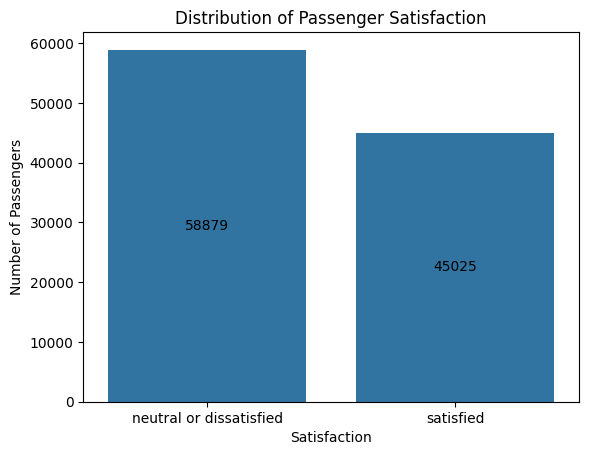

In [31]:
aa=sns.countplot(data=df, x='satisfaction')

plt.title('Distribution of Passenger Satisfaction')
plt.xlabel('Satisfaction')
plt.ylabel('Number of Passengers')
data_label(aa)
plt.show()

How many passengers were satisfied?

* Approximately 45,025 passengers (43.3%) were satisfied with their airline experience.

How many were neutral or dissatisfied?

* Approximately 58,879 passengers (56.7%) were neutral or dissatisfied.

Is the dataset balanced?

* No, the dataset is slightly imbalanced. The neutral/dissatisfied group is larger than the satisfied group. However, the imbalance is not extremely severe.

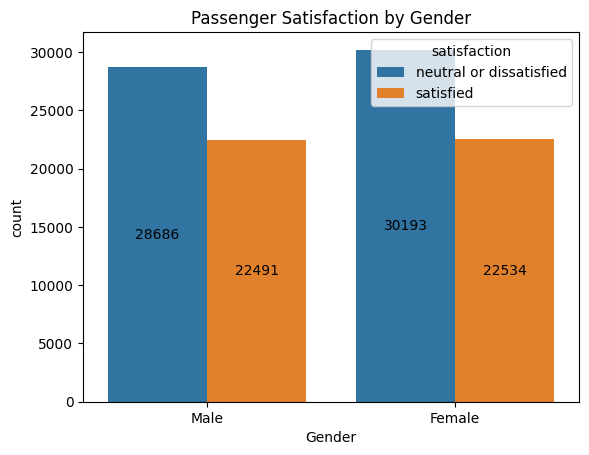

In [33]:
bb=sns.countplot(data=df, x='Gender', hue='satisfaction')

plt.title('Passenger Satisfaction by Gender')
data_label(bb)
plt.show()

**Observation :**
  * The analysis shows that passenger satisfaction levels are relatively similar between male and female passengers. Male passengers have a slightly higher satisfaction rate of **43.95%**, compared to **42.74%** among female passengers. Female passengers show a slightly higher proportion of neutral or dissatisfied responses. However, the difference is small, suggesting that gender may not be a major factor influencing passenger satisfaction.

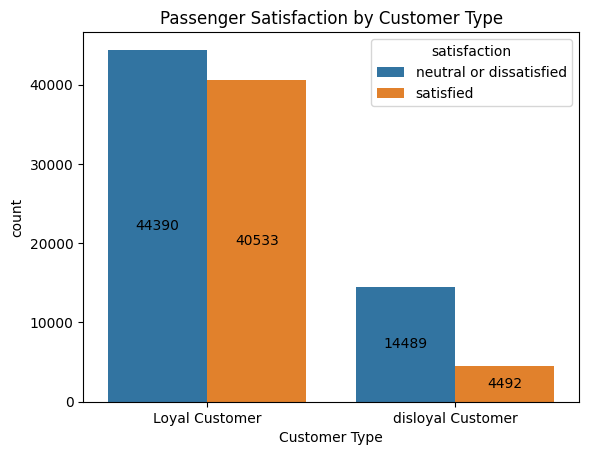

In [35]:
cc=sns.countplot(data=df, x='Customer Type', hue='satisfaction')
plt.title('Passenger Satisfaction by Customer Type')
data_label(cc)
plt.show()

Are loyal customers more satisfied than disloyal customers?

* The analysis shows that loyal customers are significantly more satisfied with the airline than disloyal customers. Approximately **47.73%** of loyal customers are satisfied, compared to only **23.67%** of disloyal customers. Disloyal customers also have a much higher proportion of neutral or dissatisfied responses **(76.33%)**. This suggests that customer loyalty is strongly associated with passenger satisfaction.

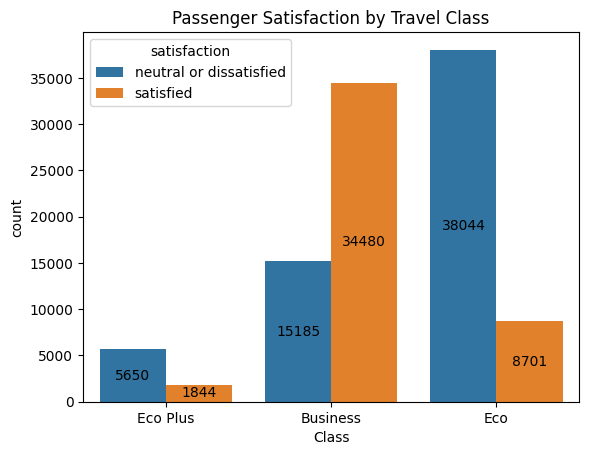

In [36]:
dd=sns.countplot(data=df, x='Class', hue='satisfaction')

plt.title('Passenger Satisfaction by Travel Class')
data_label(dd)
plt.show()

**Obserbation :**
* Business Class has the highest number of satisfied passengers.

* Eco Class has the highest number of dissatisfied or neutral passengers.

* Eco Plus passengers are also mostly neutral or dissatisfied.

* Passenger satisfaction is higher in Business Class compared to Economy classes.

# **Numerical Analysis**

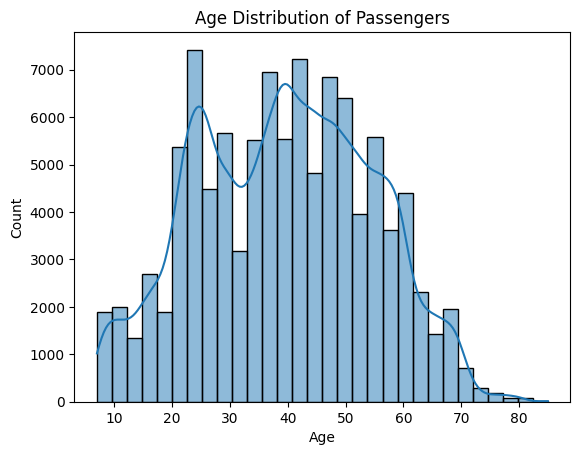

In [38]:
ee=sns.histplot(data=df, x='Age', bins=30, kde=True)

plt.title('Age Distribution of Passengers')
# data_label(ee)
plt.show()

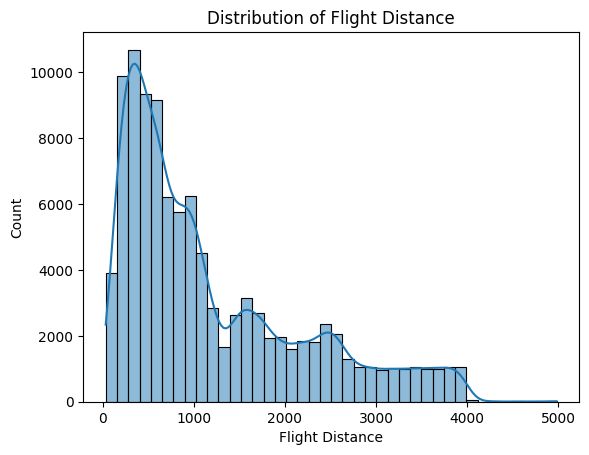

In [39]:
sns.histplot(data=df, x='Flight Distance', bins=40, kde=True)

plt.title('Distribution of Flight Distance')
plt.show()

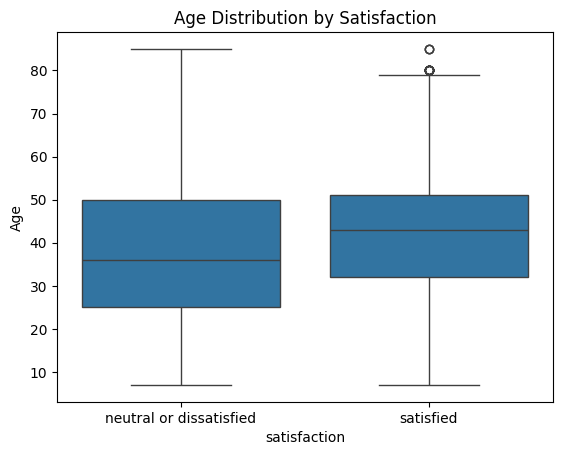

In [40]:
sns.boxplot(data=df, x='satisfaction', y='Age')

plt.title('Age Distribution by Satisfaction')
plt.show()

**Observation: Numerical Analysis**
Age Distribution:
- Most passengers are between 20 and 60 years old.
- Passengers aged around 20–25 and 35–45 form major groups.
- Very few passengers are above 70 years old.
Flight Distance:
- Most flights cover shorter distances.
- Passenger count decreases as flight distance increases.
- Long-distance flights have comparatively fewer passengers.
Age vs Satisfaction:
- Satisfied passengers tend to be slightly older.
- Neutral or dissatisfied passengers have a lower median age.
- Age may have some relationship with passenger satisfaction.

# **Service Ratings Analysis**

In [41]:
service_columns = [
    'Inflight wifi service',
    'Departure/Arrival time convenient',
    'Ease of Online booking',
    'Gate location',
    'Food and drink',
    'Online boarding',
    'Seat comfort',
    'Inflight entertainment',
    'On-board service',
    'Leg room service',
    'Baggage handling',
    'Checkin service',
    'Inflight service',
    'Cleanliness'
]

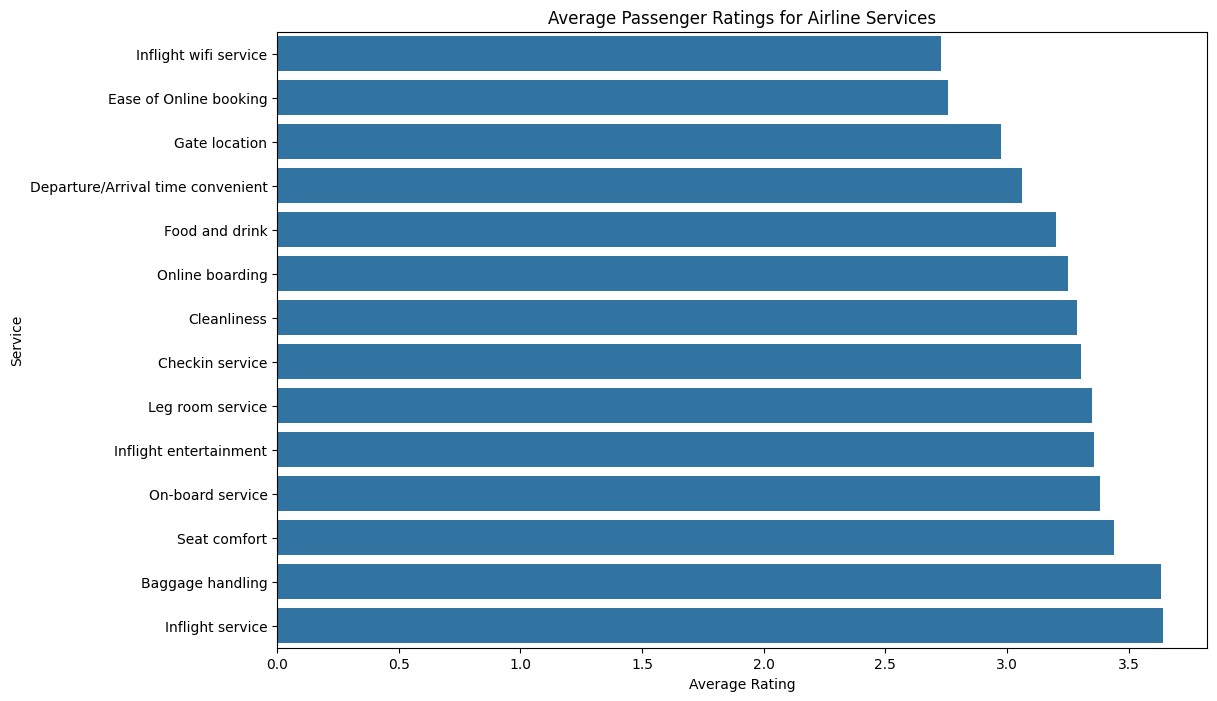

In [43]:
# Average service ratings

service_mean = df[service_columns].mean().sort_values()

plt.figure(figsize=(12, 8))

sns.barplot(
    x=service_mean.values,
    y=service_mean.index
)

plt.title('Average Passenger Ratings for Airline Services')
plt.xlabel('Average Rating')
plt.ylabel('Service')

plt.show()

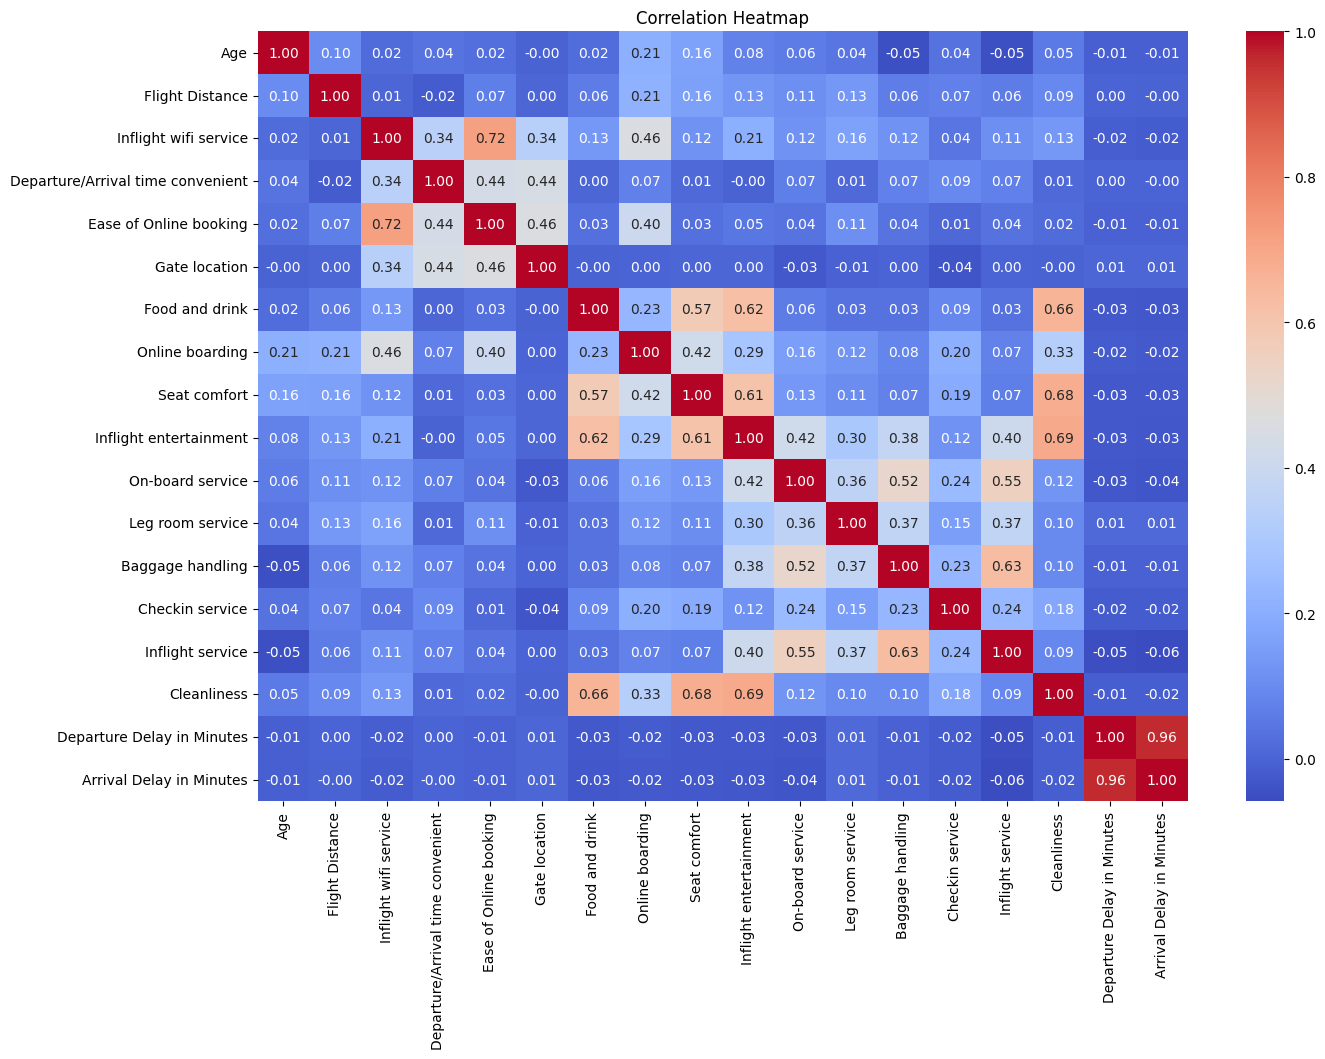

In [44]:
plt.figure(figsize=(15, 10))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

# **Overall Observation :**
- More than half of the passengers are neutral or dissatisfied.
- Loyal customers are more satisfied than disloyal customers.
- Business Class passengers show higher satisfaction than Eco and Eco Plus passengers.
- Satisfaction levels are similar between male and female passengers.
- Most passengers are between 20 and 60 years old.
- Most flights cover shorter distances.
- Inflight Wi-Fi and online booking have comparatively lower average ratings.

# **Conclusion :**
The analysis shows that passenger satisfaction is mainly related to customer loyalty and travel class. The airline should focus on improving service quality, especially Wi-Fi, online booking, and Economy Class services, to increase passenger satisfaction and customer loyalty.

# **WORK FLOW**

Data Loading — Pandas



Data Inspection — head(), tail(), info(), describe()



Data Cleaning — missing values, unnecessary columns, duplicates



Exploratory Data Analysis — Seaborn and Matplotlib



Customer Segmentation — class, age, customer type, travel type



Service Analysis — identify weak and strong services



Delay Analysis — departure and arrival delays



Insights and Recommendations — business conclusions